In [1]:
import numpy as np

def eigen(A):
    eigenvalues, eigenvectors = np.linalg.eig(A)
    eigenvalues = np.real(eigenvalues)
    eigenvectors = np.real(eigenvectors)
    
    for i in range(len(eigenvalues)):
        lam = eigenvalues[i]
        v = eigenvectors[:,i]
        formula = np.allclose(A @ v, lam * v)
        print(f"Lam = {lam}, v = {v}, check: {formula}")
        
    return eigenvalues, eigenvectors

In [2]:
vals, vecs = eigen(np.array([[4, 0], [0, 1]]))

Lam = 4.0, v = [1. 0.], check: True
Lam = 1.0, v = [0. 1.], check: True


In [3]:
vals, vecs = eigen(np.array([[2, 1], [1, 2]]))

Lam = 3.0, v = [0.70710678 0.70710678], check: True
Lam = 1.0, v = [-0.70710678  0.70710678], check: True


In [4]:
def decrypt_message(encrypted_vector, key_matrix):
    eigenvalues, eigenvectors = np.linalg.eig(key_matrix)
    inv_key = eigenvectors @ np.diag(1 / eigenvalues) @ np.linalg.inv(eigenvectors)
    sms_num = inv_key @ encrypted_vector
    codes = np.round(np.real(sms_num)).astype(int)
    result = ''.join([chr(num) for num in codes])
    return result

In [5]:
def encrypt_message(message, key_matrix):
    message_vector = np.array([ord(char) for char in message])
    eigenvalues, eigenvectors = np.linalg.eig(key_matrix)
    diagonalized_key_matrix = np.dot(np.dot(eigenvectors, np.diag(eigenvalues)), np.linalg.inv(eigenvectors))
    encrypted_vector = np.dot(diagonalized_key_matrix, message_vector)
    return encrypted_vector

message = "Hello, World!"
key_matrix = np.random.randint(0, 256, (len(message), len(message)))

encrypted = encrypt_message(message, key_matrix)
decrypted = decrypt_message(encrypted, key_matrix)

print("Original Message:", message)
print("Encrypted Message:", encrypted)
print("Decrypted Message:", decrypted)

Original Message: Hello, World!
Encrypted Message: [155205.+3.04971739e-11j 140122.+2.80128695e-11j 177037.+4.45366460e-11j
 145872.+2.26359525e-11j 104933.+2.66327308e-11j 115036.+1.81793523e-11j
 105185.+2.40058575e-11j 171369.+3.87249547e-11j 181426.+3.93066479e-11j
 141373.+3.28099313e-11j 154839.+3.76661524e-11j 159376.+3.66107855e-11j
 165805.+3.85269041e-11j]
Decrypted Message: Hello, World!


(691, 1095, 3)


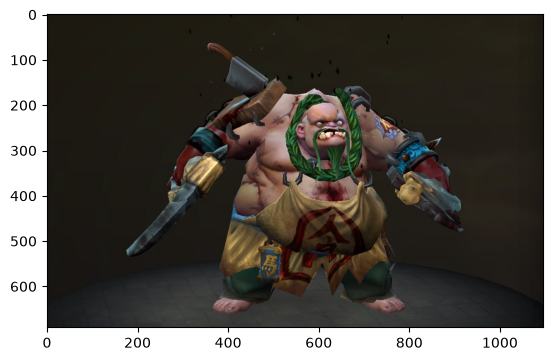

(691, 1095)
1.0


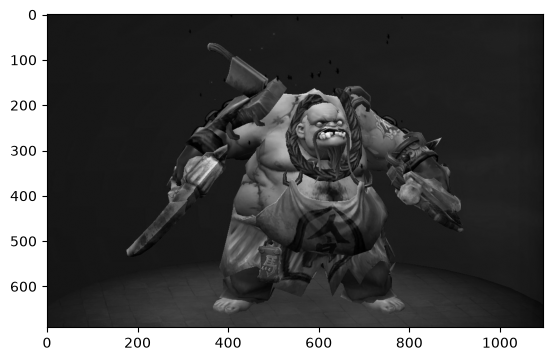

In [6]:
from matplotlib.image import imread
import matplotlib.pyplot as plt
image_raw = imread("photo.jpg")
print(image_raw.shape)
plt.imshow(image_raw)
plt.show()
image_sum = image_raw.sum(axis=2)
print(image_sum.shape)
image_bw = image_sum/image_sum.max()
print(image_bw.max())
plt.imshow(image_bw, cmap='gray')
plt.show()